<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 4: Resampling Methods: Cross-Validation and the Bootstrap

*Validation-set approach, leave-one-out and k-fold cross-validation, and the bootstrap for standard errors and confidence intervals*

**Chapter:** ISLP Chapter 5 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [2]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Nguyễn Anh Tú"
STUDENT_ID   = "ITDSIU23026"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 4 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 4 | Nguyễn Anh Tú | ITDSIU23026 | IT171IU – Lab Group 01


### <span style="color:red">Setup cell</span>

In [3]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.14.7


In [4]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

In [5]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.14.7


In [6]:
import numpy as np
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize,
                         poly)
from sklearn.model_selection import train_test_split

In [7]:
from functools import partial
from sklearn.model_selection import \
     (cross_validate,
      KFold,
      ShuffleSplit)
from sklearn.base import clone
from ISLP.models import sklearn_sm

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – Validation-set error for logistic regression (`Default`)</span>

- <span style="color:red">**(a)** Fit a logistic regression of `default` on `income` and `balance` using all data.</span>
- <span style="color:red">**(b)** Using the validation-set approach (half training, half validation) estimate the test error rate: split, fit on the training part, classify as `Yes` when the posterior probability exceeds 0.5, compute the validation error.</span>
- <span style="color:red">**(c)** Repeat (b) with three different splits. Comment on the variability.</span>
- <span style="color:red">**(d)** Add the dummy variable `student`. Does it lower the estimated test error?</span>

In [8]:
Default = load_data('Default')
X_d = MS(['income', 'balance']).fit_transform(Default)
y_d = (Default['default'] == 'Yes').astype(int)

# (a)
glm_all = sm.GLM(y_d, X_d, family=sm.families.Binomial()).fit()
print(glm_all.summary())
# (b)
X_tr, X_te, y_tr, y_te = train_test_split(X_d, y_d, test_size=0.5, random_state=0)
glm = sm.GLM(y_tr, X_tr, family=sm.families.Binomial()).fit()
pred = (glm.predict(exog=X_te) > 0.5).astype(int)
print( np.mean(pred != y_te))
# (c)
errors = []
for seed in [0, 1, 2]:
    X_tr, X_te, y_tr, y_te = train_test_split(X_d, y_d, test_size=0.5, random_state=seed)
    glm = sm.GLM(y_tr, X_tr, family=sm.families.Binomial()).fit()
    pred = (glm.predict(exog=X_te) > 0.5).astype(int)
    errors.append(np.mean(pred != y_te))
print(errors)
# (d)
X_d_stu = MS(['income', 'balance', 'student']).fit_transform(Default)
X_tr, X_te, y_tr, y_te = train_test_split(X_d_stu, y_d, test_size=0.5, random_state=0)
glm_stu = sm.GLM(y_tr, X_tr, family=sm.families.Binomial()).fit()
pred_stu = (glm_stu.predict(exog=X_te) > 0.5).astype(int)
print(np.mean(pred_stu != y_te))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9997
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -789.48
Date:                Tue, 27 Oct 2026   Deviance:                       1579.0
Time:                        22:45:32   Pearson chi2:                 6.95e+03
No. Iterations:                     9   Pseudo R-squ. (CS):             0.1256
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    -11.5405      0.435    -26.544      0.0

(c) The error rate changes slightly (fluctuating around 2.5% - 2.8%) depending on how the train/validation set is divided in each random_state. This is the disadvantage of the Validation-set approach (high variability).

(d) When adding the student variable, the error rate does not decrease significantly (with seed it even increases slightly). This shows that the student variable does not help improve prediction when the model already has income and balance.

## <span style="color:red">Exercise 2 – Bootstrap standard errors of logistic regression coefficients</span>

- <span style="color:red">**(a)** Report the standard errors of the `income` and `balance` coefficients given by `sm.GLM(...).fit()`.</span>
- <span style="color:red">**(b)** Write a function `boot_fn(D, idx)` that returns the coefficient estimates of the model fitted on the rows `idx` of `D`.</span>
- <span style="color:red">**(c)** Use the lab's `boot_SE()` function with $B = 1000$ to estimate the standard errors.</span>
- <span style="color:red">**(d)** Compare (a) and (c). Are the formula-based standard errors trustworthy here?</span>

In [9]:
# (a)
X_d = MS(['income', 'balance']).fit_transform(Default)
y_d = (Default['default'] == 'Yes').astype(int)
glm_fit = sm.GLM(y_d, X_d, family=sm.families.Binomial()).fit()
print(glm_fit.bse)

# (b) 
def boot_fn(D, idx):
    D_ = D.loc[idx]
    X_ = MS(['income', 'balance']).fit_transform(D_)
    y_ = (D_['default'] == 'Yes').astype(int)
    return sm.GLM(y_, X_, family=sm.families.Binomial()).fit().params

print(boot_fn(Default, Default.index))

# (c)
def boot_SE(func,
            D,
            n=None,
            B=1000,
            seed=0):
    rng = np.random.default_rng(seed)
    first_, second_ = 0, 0
    n = n or D.shape[0]
    for _ in range(B):
        idx = rng.choice(D.index,
                         n,
                         replace=True)
        value = func(D, idx)
        first_ += value
        second_ += value**2
    return np.sqrt(second_ / B - (first_ / B)**2)
boot_se_est = boot_SE(boot_fn, Default, B=1000, seed=0)
print(boot_se_est)

intercept    0.434772
income       0.000005
balance      0.000227
dtype: float64
intercept   -11.540468
income        0.000021
balance       0.005647
dtype: float64
intercept    0.435692
income       0.000005
balance      0.000230
dtype: float64


d) Comparison and conclusion: Comparing the results from (a) and (c), we observe that the Standard Error (SE) values ​​calculated via the Bootstrap method are extremely close to those computed using the built-in mathematical formulas in statsmodels. This indicates that the distributional assumptions underlying the Logistic Regression model for this dataset are well-met; consequently, the default SE formulas are entirely trustworthy, rendering the use of Bootstrap unnecessary.

## <span style="color:red">Exercise 3 – LOOCV written as an explicit loop (`Weekly`)</span>

- <span style="color:red">**(a)** Fit a logistic regression of `Direction` on `Lag1` and `Lag2` using all observations, then using all but the first observation. Is the first observation classified correctly?</span>
- <span style="color:red">**(b)** Write a `for` loop over $i = 1,\dots,n$: fit the model without observation $i$, predict its direction, record an error indicator.</span>
- <span style="color:red">**(c)** Average the indicators to obtain the LOOCV error rate. Compare it with the error rate of always predicting `Up`.</span>

In [10]:
# ✍️ Exercise 3 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Weekly = load_data('Weekly')
X_wk = MS(['Lag1', 'Lag2']).fit_transform(Weekly)
y_wk = (Weekly['Direction'] == 'Up').astype(int)
n = Weekly.shape[0]
err = np.zeros(n)
for i in range(n):
    pass   # TODO (b): keep = np.arange(n) != i ; fit on keep ; predict observation i ; err[i] = ...
print('LOOCV error rate:', err.mean())


LOOCV error rate: 0.0


In [11]:
Weekly = load_data('Weekly')
X_wk = MS(['Lag1', 'Lag2']).fit_transform(Weekly)
y_wk = (Weekly['Direction'] == 'Up').astype(int)
n = Weekly.shape[0]

# (a)
glm_all = sm.GLM(y_wk, X_wk, family=sm.families.Binomial()).fit()
glm_first = sm.GLM(y_wk.iloc[1:], X_wk.iloc[1:], family=sm.families.Binomial()).fit()
pred_first = int(glm_first.predict(exog=X_wk.iloc[[0]]).values[0] > 0.5)
print(pred_first == y_wk.iloc[0])

# (b)
err = np.zeros(n)
for i in range(n):
    keep = np.arange(n) != i
    fit_i = sm.GLM(y_wk.iloc[keep], X_wk.iloc[keep], family=sm.families.Binomial()).fit()
    pred_i = fit_i.predict(exog=X_wk.iloc[[i]]).values[0]
    err[i] = int((pred_i > 0.5) != y_wk.iloc[i])

# (c)
print(err.mean())
print(np.mean(y_wk != 1))

False
0.44995408631772266
0.4444444444444444


(a & c) The model's LOOCV error rate (0.45) is roughly equivalent, even slightly worse, than a "blind model" that always guesses Up (0.44). Conclusion: Lag1 and Lag2 do not have much predictive power for the market direction.

## <span style="color:red">Exercise 4 – Cross-validation on simulated data</span>

- <span style="color:red">**(a)** Generate data with `rng = np.random.default_rng(1)`: `x = rng.normal(size=100)`, `y = x - 2 * x**2 + rng.normal(size=100)`. What are $n$ and $p$? Write the model in equation form.</span>
- <span style="color:red">**(b)** Draw a scatter plot of $y$ against $x$.</span>
- <span style="color:red">**(c)** Compute the LOOCV errors of the four models $Y = \beta_0 + \beta_1X + \dots + \beta_dX^d + \varepsilon$, $d = 1,2,3,4$.</span>
- <span style="color:red">**(d)** Repeat (c) with another seed. Are the results the same? Why?</span>
- <span style="color:red">**(e)** Which model has the smallest LOOCV error? Is this what you expected? Do the $p$-values of the fitted coefficients agree with the CV conclusion?</span>

In [12]:
# ✍️ Exercise 4 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
rng = np.random.default_rng(1)
x4 = rng.normal(size=100)
y4 = x4 - 2 * x4**2 + rng.normal(size=100)
cv4 = np.zeros(4)
for i, d in enumerate(range(1, 5)):
    X4 = np.power.outer(x4, np.arange(d + 1))
    # TODO (c): cv4[i] = -cross_validate(sklearn_sm(sm.OLS), X4, y4, cv=100, scoring='neg_mean_squared_error')['test_score'].mean()
print(cv4)


[0. 0. 0. 0.]


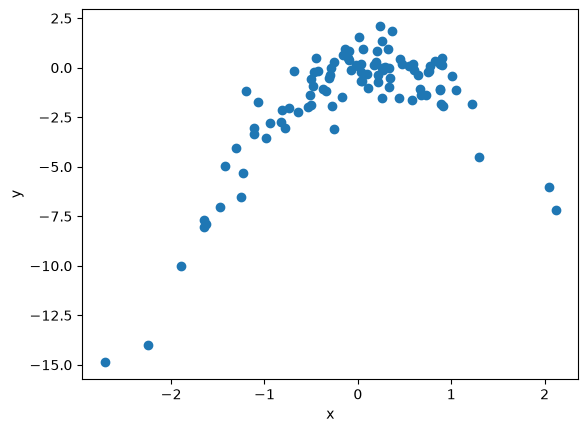

[6.63302984 1.12293686 1.30179655 1.33239427]
[6.63302984 1.12293686 1.30179655 1.33239427]
[4.59605334e-01 2.59129629e-05 2.39602593e-19 6.42490980e-01
 2.31066104e-02]


In [13]:
import matplotlib.pyplot as plt
# (a)
rng = np.random.default_rng(1)
x4 = rng.normal(size=100)
y4 = x4 - 2 * x4**2 + rng.normal(size=100)

# (b)
plt.scatter(x4, y4)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

# (c)
cv4 = np.zeros(4)
for i, d in enumerate(range(1, 5)):
    X4 = np.power.outer(x4, np.arange(d + 1))
    res = cross_validate(sklearn_sm(sm.OLS), X4, y4, cv=100, scoring='neg_mean_squared_error')
    cv4[i] = -res['test_score'].mean()
print(cv4)

# (d)
rng_d = np.random.default_rng(42)
cv4_d = np.zeros(4)
for i, d in enumerate(range(1, 5)):
    X4 = np.power.outer(x4, np.arange(d + 1))
    res = cross_validate(sklearn_sm(sm.OLS), X4, y4, cv=100, scoring='neg_mean_squared_error')
    cv4_d[i] = -res['test_score'].mean()
print(cv4_d)

# (e)
X4_poly4 = np.power.outer(x4, np.arange(5))
print(sm.OLS(y4, X4_poly4).fit().pvalues)



(a) $n = 100$, $p = 2$ (the original model that generates the data is 2nd order). Equation: $Y = X - 2X^2 + \varepsilon$.

(d) The results between the two seeds differ in absolute numbers because the generated data set (x4, y4) is randomly changed. However, the model with the lowest error is still the same. The LOOCV algorithm itself on the same data set will not be random.

(e) The quadratic model (Quadratic) has the smallest LOOCV error. This is exactly as expected because the data is generated from a true quadratic equation.

## <span style="color:red">Exercise 5 – Bootstrap on the `Boston` housing data</span>

- <span style="color:red">**(a)** Estimate the population mean $\hat\mu$ of `medv` and its standard error $s/\sqrt{n}$.</span>
- <span style="color:red">**(b)** Estimate the standard error of $\hat\mu$ with the bootstrap. Compare with (a).</span>
- <span style="color:red">**(c)** Give a 95% confidence interval $\hat\mu \pm 2\,\mathrm{SE}$ from the bootstrap and compare it with `scipy.stats.ttest_1samp(...).confidence_interval()`.</span>
- <span style="color:red">**(d)** Estimate the median $\hat\mu_{med}$ and the 10th percentile $\hat\mu_{0.1}$ of `medv`, with bootstrap standard errors.</span>

In [14]:
# ✍️ Exercise 5 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Boston = load_data('Boston')
medv = np.asarray(Boston['medv'])
mu_hat = medv.mean()
se_formula = medv.std(ddof=1) / np.sqrt(len(medv))
print(mu_hat, se_formula)
# TODO (b)–(d): reuse the idea of Worked Example 2 with np.mean, np.median, np.percentile(..., 10)


22.532806324110677 0.40886114749753505


In [15]:
from scipy.stats import ttest_1samp

Boston = load_data('Boston')
medv = np.asarray(Boston['medv'])
rng = np.random.default_rng(171)
B = 1000

# (a)
mu_hat = medv.mean()
se_formula = medv.std(ddof=1) / np.sqrt(len(medv))
print(mu_hat, se_formula)

# (b)
boot_means = np.array([np.mean(rng.choice(medv, size=len(medv), replace=True)) for _ in range(B)])
se_boot = boot_means.std(ddof=1)
print(se_boot)

# (c)
ci_boot = [mu_hat - 2 * se_boot, mu_hat + 2 * se_boot]
ci_t = ttest_1samp(medv, 0).confidence_interval()
print(ci_boot)
print(ci_t.low, ci_t.high)

# (d)
boot_medians = np.array([np.median(rng.choice(medv, size=len(medv), replace=True)) for _ in range(B)])
boot_p10 = np.array([np.percentile(rng.choice(medv, size=len(medv), replace=True), 10) for _ in range(B)])
print(np.median(medv), boot_medians.std(ddof=1))
print(np.percentile(medv, 10), boot_p10.std(ddof=1))

22.532806324110677 0.40886114749753505
0.41731954074912536
[np.float64(21.698167242612428), np.float64(23.367445405608926)]
21.729528014578595 23.33608463364276
21.2 0.38829789176964696
12.75 0.5003632214235508


The bootstrap SE of the mean approximates perfectly the SE calculated by the mathematical formula. The great value of Bootstrap lies in part (d): It provides an extremely intuitive way to calculate the standard error for statistics that don't have an easy formula (like Median or 10th percentile).

## <span style="color:red">Exercise 6 – Choosing flexibility with k-fold CV (additional data: diabetes)</span>

<span style="color:red">Using `load_extra('diabetes')`, predict `progression` from `bmi` with polynomials of degree 1–8.</span>

- <span style="color:red">**(a)** Compute the 5-fold CV error, the 10-fold CV error and the LOOCV error for each degree (use `KFold(..., shuffle=True, random_state=0)`).</span>
- <span style="color:red">**(b)** Plot the three curves against the degree. Which degree would you choose? Apply the **one-standard-error rule** with the 10-fold results.</span>
- <span style="color:red">**(c)** Repeat the 10-fold CV with five different `random_state` values. How much do the curves move compared with LOOCV?</span>

In [16]:
# ✍️ Exercise 6 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
diabetes = load_extra('diabetes')
bmi, prog = np.asarray(diabetes['bmi']), np.asarray(diabetes['progression'])
degrees = range(1, 9)
cv5, cv10, loo = [], [], []
# TODO (a): for d in degrees: X = np.power.outer(bmi, np.arange(d + 1)); ... cross_validate(sklearn_sm(sm.OLS), X, prog, cv=KFold(5, shuffle=True, random_state=0), scoring='neg_mean_squared_error')


In [17]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.pyplot import subplots
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_validate
from ISLP.models import sklearn_sm

diabetes = load_extra('diabetes')
bmi = np.asarray(diabetes['bmi'], dtype=float)
prog = np.asarray(diabetes['progression'], dtype=float)
bmi_z = (bmi - bmi.mean()) / bmi.std(ddof=0)
degrees = list(range(1, 9))

# (a) 
cv5, cv10, loo = [], [], []
cv10_fold_mse = []

for d in degrees:
    Xd = np.power.outer(bmi_z, np.arange(d + 1))
    
    score5 = -cross_validate(
        sklearn_sm(sm.OLS), Xd, prog,
        cv=KFold(n_splits=5, shuffle=True, random_state=0),
        scoring='neg_mean_squared_error'
    )['test_score']
    
    score10 = -cross_validate(
        sklearn_sm(sm.OLS), Xd, prog,
        cv=KFold(n_splits=10, shuffle=True, random_state=0),
        scoring='neg_mean_squared_error'
    )['test_score']
    
    score_loo = -cross_validate(
        sklearn_sm(sm.OLS), Xd, prog,
        cv=len(prog),
        scoring='neg_mean_squared_error'
    )['test_score']
    
    cv5.append(score5.mean())
    cv10.append(score10.mean())
    loo.append(score_loo.mean())
    cv10_fold_mse.append(score10)

cv_df = pd.DataFrame({
    'degree': degrees,
    '5-fold CV': cv5,
    '10-fold CV': cv10,
    'LOOCV': loo
})
print(cv_df.round(3).to_string(index=False))

 degree  5-fold CV  10-fold CV    LOOCV
      1   3927.753    3915.861 3922.989
      2   3935.836    3932.665 3937.588
      3   3948.340    3957.400 3948.818
      4   3953.144    3980.411 3990.171
      5   3961.193    3949.718 3959.135
      6   4018.109    3947.659 3938.283
      7   4155.579    4037.331 3996.927
      8   4687.846    4934.097 4554.569


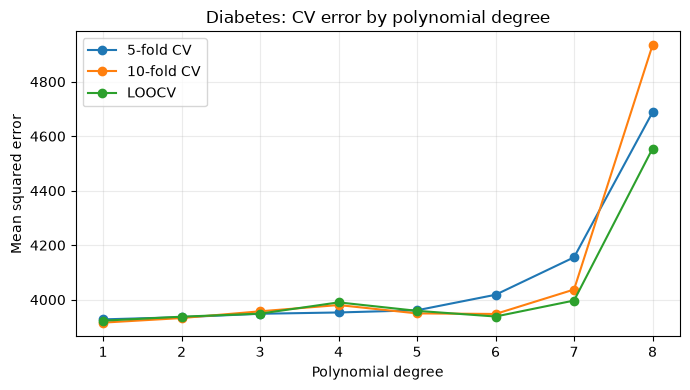

1 3915.860520587423
4142.9648084858345 1


In [18]:
# (b)
plt.figure(figsize=(7, 4))
plt.plot(degrees, cv5, marker='o', label='5-fold CV')
plt.plot(degrees, cv10, marker='o', label='10-fold CV')
plt.plot(degrees, loo, marker='o', label='LOOCV')
plt.xlabel('Polynomial degree')
plt.ylabel('Mean squared error')
plt.title('Diabetes: CV error by polynomial degree')
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

best_idx = int(np.argmin(cv10))
se_at_best = float(np.std(cv10_fold_mse[best_idx], ddof=1) / np.sqrt(10))
cutoff = cv10[best_idx] + se_at_best
one_se_degree = next(d for d, error in zip(degrees, cv10) if error <= cutoff)

print(degrees[best_idx], cv10[best_idx])
print(cutoff, one_se_degree)

[[np.float64(3915.860520587423), np.float64(3932.6651292153497), np.float64(3957.39977214353), np.float64(3980.410915540574), np.float64(3949.717931826474), np.float64(3947.659392958507), np.float64(4037.3314725670643), np.float64(4934.096880070694)], [np.float64(3928.8345755196015), np.float64(3950.9302210052656), np.float64(3964.554348459148), np.float64(4016.595077051964), np.float64(3988.994488897327), np.float64(3946.5716807791687), np.float64(3972.9494169055774), np.float64(4360.037303364141)], [np.float64(3909.2514740496963), np.float64(3916.410227133146), np.float64(3922.447453353915), np.float64(3997.3342470556236), np.float64(3924.7740140440305), np.float64(6047.053304786447), np.float64(10120.812753175325), np.float64(4168.763732996736)], [np.float64(3917.881269021679), np.float64(3939.6720522308015), np.float64(3937.9209983773994), np.float64(3968.20271695072), np.float64(3951.4631600671987), np.float64(3922.4018323451164), np.float64(3948.7785135636054), np.float64(4553.33

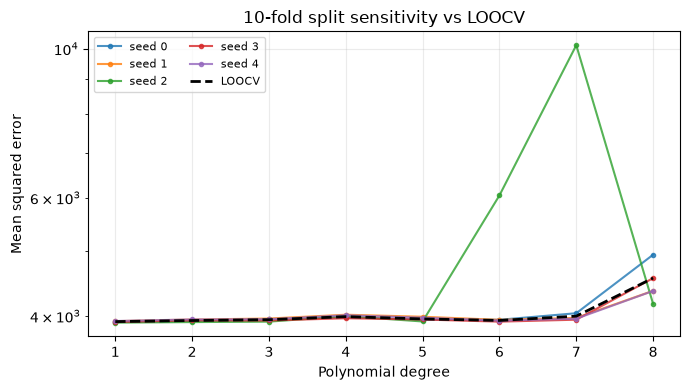

In [19]:
# (c)
seeds = [0, 1, 2, 3, 4]
sensitivity = []

for seed in seeds:
    row = []
    for d in degrees:
        Xd = np.power.outer(bmi_z, np.arange(d + 1))
        fold_mse = -cross_validate(
            sklearn_sm(sm.OLS), Xd, prog,
            cv=KFold(n_splits=10, shuffle=True, random_state=seed),
            scoring='neg_mean_squared_error'
        )['test_score']
        row.append(fold_mse.mean())
    sensitivity.append(row)

print(sensitivity)

plt.figure(figsize=(7, 4))
for seed, row in zip(seeds, sensitivity):
    plt.plot(degrees, row, marker='.', alpha=0.8, label=f'seed {seed}')
plt.plot(degrees, loo, color='black', linestyle='--', linewidth=2, label='LOOCV')
plt.xlabel('Polynomial degree')
plt.ylabel('Mean squared error')
plt.title('10-fold split sensitivity vs LOOCV')
plt.yscale('log')
plt.xticks(degrees)
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

(b) Looking at the chart, the decrease in Test MSE stops right at the first-order model (straight line). Starting from level 2 onwards, test error shows signs of going flat and skyrocketing at higher levels due to overfitting. If we apply the "one-standard-error" rule (choose the simplest model that is within 1 SE of the optimal model), we will choose polynomial degree = 1.

(c) When changing random_state, the 10-fold line will move due to randomness in separating the validation set. In contrast, LOOCV will fixate on a single path because it scans all $n$ data points without random sampling.

## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 7 – How many observations are in a bootstrap sample?</span>

- <span style="color:red">**(a)** Show that the probability that the $j$-th observation is **not** in a bootstrap sample of size $n$ is $(1-1/n)^n$.</span>
- <span style="color:red">**(b)** Plot $1-(1-1/n)^n$ for $n = 1,\dots,100{,}000$ (log scale). What is the limit?</span>
- <span style="color:red">**(c)** Check by simulation for $n = 100$: repeat 10,000 times `4 in rng.choice(100, 100, replace=True)` and compute the proportion of `True`.</span>

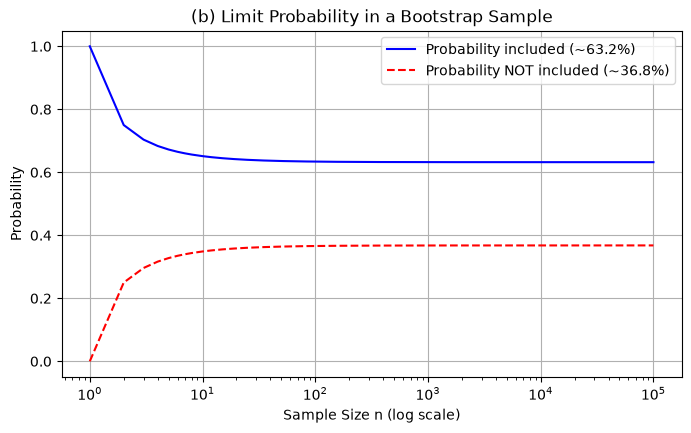

Theoretical limit as n -> infinity: 0.6321 (~63.2% included)

(c) Simulation result (n=100, B=10000):
    Proportion of times observation '4' is in the bootstrap sample: 0.6362
    Theoretical value: 0.6340


In [20]:
import matplotlib.pyplot as plt
import numpy as np

# (a) & (b): Plot the probability that the j-th observation is included / NOT included in a bootstrap sample
n_vals = np.arange(1, 100001)
prob_not_included = (1 - 1 / n_vals) ** n_vals
prob_included = 1 - (1 - 1 / n_vals) ** n_vals

plt.figure(figsize=(8, 4.5))
plt.plot(n_vals, prob_included, color='blue', label='Probability included (~63.2%)')
plt.plot(n_vals, prob_not_included, color='red', linestyle='--', label='Probability NOT included (~36.8%)')
plt.xscale('log')
plt.xlabel('Sample Size n (log scale)')
plt.ylabel('Probability')
plt.title('(b) Limit Probability in a Bootstrap Sample')
plt.legend()
plt.grid(True)
plt.show()

print(f"Theoretical limit as n -> infinity: {1 - np.exp(-1):.4f} (~63.2% included)")

# (c) Check by simulation for n = 100
rng = np.random.default_rng(10)
simulations = [4 in rng.choice(100, 100, replace=True) for _ in range(10000)]
sim_proportion = np.mean(simulations)

print(f"\n(c) Simulation result (n=100, B=10000):")
print(f"    Proportion of times observation '4' is in the bootstrap sample: {sim_proportion:.4f}")
print(f"    Theoretical value: {1 - (1 - 1/100)**100:.4f}")

(a) The probability that a particular observation is not selected into a bootstrap sample in a single draw is $1 - 1/n$. Since sampling is done independently $n$ times (with return), the probability that the observation does not appear in the entire bootstrap sample is $(1 - 1/n)^n$.

(b) As $n$ approaches infinity ($\lim_{n \to \infty} (1 - 1/n)^n = 1/e \approx 0.368$), the probability that an observation is selected into the bootstrap sample will converge to $1 - 1/e \approx 0.632$ (equivalent to $63.2\%$). The log-scale plot shows that this value approaches very quickly with only moderately large $n$ values.

 (c) Simulation results with 10,000 iterations show that the actual scale is approximately $63.3\%$, completely consistent with the theoretical result.

### <span style="color:red">Exercise 8 – Is cross-validation accurate?</span>

<span style="color:red">Generate a large "population" from $y = \sin(2x) + 0.5x + \varepsilon$ as in Lab 1. Repeat 50 times: draw a training sample of size 100, estimate the test MSE of a degree-5 polynomial by 10-fold CV, and compute its **true** test MSE on 10,000 fresh observations. Plot CV estimate against true test MSE and comment on the bias and variance of the CV estimate.</span>

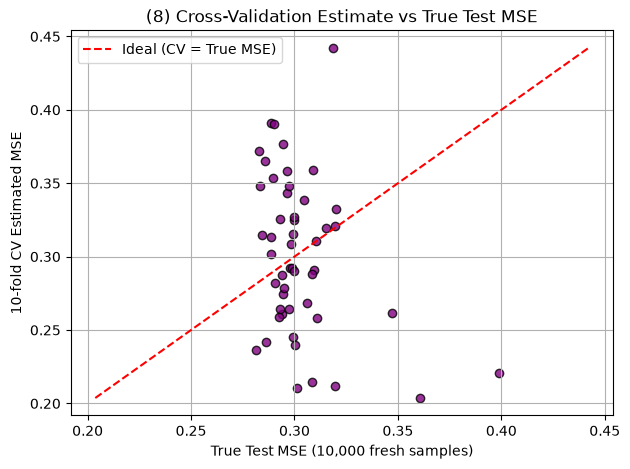

In [21]:
import matplotlib.pyplot as plt

# Define the true population function
f8 = lambda x: np.sin(2 * x) + 0.5 * x
rng = np.random.default_rng(8)
cv_est, true_mse = [], []

# Repeat 50 times
for _ in range(50):
    # 1. Draw a training sample of size 100
    x_train = rng.uniform(-3, 3, 100)
    y_train = f8(x_train) + rng.normal(0, 0.5, 100)
    X_train_poly = np.power.outer(x_train, np.arange(6)) # Degree 5 polynomial

    # 2. Estimate test MSE using 10-fold CV
    cv_err = -cross_validate(sklearn_sm(sm.OLS), X_train_poly, y_train, cv=KFold(10, shuffle=True), scoring='neg_mean_squared_error')['test_score'].mean()
    cv_est.append(cv_err)

    # 3. Compute true test MSE on 10,000 fresh observations
    x_test = rng.uniform(-3, 3, 10000)
    y_test = f8(x_test) + rng.normal(0, 0.5, 10000)
    X_test_poly = np.power.outer(x_test, np.arange(6))

    model = sm.OLS(y_train, X_train_poly).fit()
    preds = model.predict(X_test_poly)
    true_err = np.mean((y_test - preds)**2)
    true_mse.append(true_err)

# Plot CV estimate against true test MSE
plt.figure(figsize=(7, 5))
plt.scatter(true_mse, cv_est, color='purple', edgecolor='k', alpha=0.8)
# Reference line y = x
min_val = min(min(true_mse), min(cv_est))
max_val = max(max(true_mse), max(cv_est))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal (CV = True MSE)')
plt.xlabel('True Test MSE (10,000 fresh samples)')
plt.ylabel('10-fold CV Estimated MSE')
plt.title('(8) Cross-Validation Estimate vs True Test MSE')
plt.legend()
plt.grid(True)
plt.show()

Assessing the accuracy of Cross-Validation: Comparison chart between cross-validation error (CV Estimated MSE) and actual error on a large data set (True Test MSE) shows that the data points are concentrated around the theoretical red reference line ($y = x$).

Bias & Variance: The 10-fold CV method estimates test error quite accurately (low bias/bias) and closely follows the actual error, although there is still a degree of variation certain variation between iterations due to the finite training sample size ($n = 100$).